<a href="https://colab.research.google.com/github/a-memoir/Automated-Medical-Report-NNH/blob/main/15oct.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

Mounted at /content/drive


In [3]:
# STEP 1 — read-only environment & file check (no checkpoints loaded, no test cases used)
import os, datetime, platform, subprocess
from google.colab import drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
print("Drive mounted:", os.path.ismount("/content/drive"))

ROOT = "/content/drive/MyDrive/NoiSoi_Matching"
V5 = f"{ROOT}/baseline_model_v5"
print("Project root exists:", os.path.isdir(ROOT))

def info(p):
    if not os.path.exists(p):
        return f"MISSING  {p}"
    st = os.stat(p)
    ts = datetime.datetime.fromtimestamp(st.st_mtime).strftime("%Y-%m-%d %H:%M:%S")
    kind = "DIR " if os.path.isdir(p) else "FILE"
    return f"{kind} {st.st_size:>14,d}  {ts}  {p.replace(ROOT + '/', '')}"

print("\n== Key files ==")
for rel in ["baseline_model_v5/test_predictions_712.csv",
            "baseline_model_v5/checkpoints/best.pt",
            "baseline_model_v5/checkpoints/last.pt",
            "baseline_model_v5/diagnostics/v5_final_training_summary.json",
            "baseline_model_v5/runtime_state/paths.json",
            "baseline_model_v4/v4_training_manifest.csv",
            "v3_ontology_v2/v3_structured_targets_v2_2.csv",
            "baseline_model_v4/diagnostics/frozen_concept_ontology_mapping.csv"]:
    print(info(f"{ROOT}/{rel}"))

print("\n== diagnostics/ subfolders ==")
diag = f"{V5}/diagnostics"
for name in sorted(os.listdir(diag)):
    print(info(f"{diag}/{name}"))

for sub in ["audit_20261015", "audit_20261015_review"]:
    d = f"{diag}/{sub}"
    print(f"\n== {sub} ==")
    if not os.path.isdir(d):
        print("  (not present)")
        continue
    for name in sorted(os.listdir(d)):
        print(" ", info(f"{d}/{name}"))

print("\n== Runtime ==")
print("Python", platform.python_version())
try:
    import psutil
    print(f"RAM total: {psutil.virtual_memory().total/1e9:.1f} GB")
except Exception as e:
    print("RAM: n/a", e)
try:
    r = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                       capture_output=True, text=True)
    print("GPU:", r.stdout.strip() or "none (CPU runtime)")
except FileNotFoundError:
    print("GPU: none (CPU runtime)")
print("\nSTEP 1 DONE")


Drive mounted: True
Project root exists: True

== Key files ==
FILE         62,941  2026-09-30 16:34:27  baseline_model_v5/test_predictions_712.csv
FILE  4,640,037,647  2026-09-29 04:20:44  baseline_model_v5/checkpoints/best.pt
FILE  4,640,037,647  2026-09-29 04:25:51  baseline_model_v5/checkpoints/last.pt
FILE            649  2026-09-29 04:23:10  baseline_model_v5/diagnostics/v5_final_training_summary.json
FILE            719  2026-09-28 08:24:55  baseline_model_v5/runtime_state/paths.json
FILE      1,921,940  2026-09-22 16:26:41  baseline_model_v4/v4_training_manifest.csv
FILE      6,233,626  2026-09-21 16:51:22  v3_ontology_v2/v3_structured_targets_v2_2.csv
FILE          1,974  2026-09-22 16:26:41  baseline_model_v4/diagnostics/frozen_concept_ontology_mapping.csv

== diagnostics/ subfolders ==
DIR           4,096  2026-10-14 20:45:58  baseline_model_v5/diagnostics/audit_20261015
DIR           4,096  2026-10-15 12:59:28  baseline_model_v5/diagnostics/audit_20261015_review
FILE       

In [5]:
# STEP 2 — understand data (read-only)
import os, json, glob, pandas as pd
from google.colab import drive
if not os.path.ismount("/content/drive"): drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/NoiSoi_Matching"; V5 = f"{ROOT}/baseline_model_v5"
REV = f"{V5}/diagnostics/audit_20261015_review"
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)

print("## lookup vs V5 overall"); print(pd.read_csv(glob.glob(f"{REV}/v5_vs_lookup_overall_*.csv")[0]).to_string())
print("## paths.json"); print(open(f"{V5}/runtime_state/paths.json").read()[:700])
print("## summary.json"); print(open(f"{V5}/diagnostics/v5_final_training_summary.json").read()[:650])

prov = open(glob.glob(f"{REV}/provenance_review_*.txt")[0], encoding="utf-8", errors="replace").read()
print("## provenance review: section headers")
for ln in prov.splitlines():
    if ln.startswith(("#", "==", "CONCLUSION", "VERDICT", "SUMMARY")): print("  ", ln[:120])

m = pd.read_csv(f"{ROOT}/baseline_model_v4/v4_training_manifest.csv")
print("## V4 manifest", m.shape); print(list(m.columns))
print(m.split.value_counts().to_dict(), "| patient groups:", m.patient_group_id.nunique())
leak = m.groupby("patient_group_id").split.nunique(); print("groups spanning >1 split:", int((leak > 1).sum()))
print("unique ket_luan:", m.ket_luan.nunique(), "| top10 share:", round(m.ket_luan.value_counts().head(10).sum() / len(m), 3))
print("ket_luan len (chars) quantiles:", m.ket_luan.str.len().quantile([.1, .5, .9, .99]).round().tolist())

fm_path = f"{ROOT}/final_manifest/final_dataset_manifest.csv"
fm = pd.read_csv(fm_path, nrows=200000)
print("## final image manifest", fm.shape); print(list(fm.columns))
SAFE_COLS = ["case_id", "image_order", "n_images_case", "is_no_signal_v3", "image_status", "split"]  # no names/paths (rule 8)
print(fm[SAFE_COLS].head(3).to_string())

mp = pd.read_csv(f"{ROOT}/baseline_model_v4/diagnostics/frozen_concept_ontology_mapping.csv")
print("## ontology mapping", mp.shape, list(mp.columns)); print(mp.head(48).to_string()[:2500])
print("STEP 2 DONE")


## lookup vs V5 overall
                 method   exact  token_f1  unique_outputs
0              V5 model  0.1896    0.5979              16
1  Lookup (V5's region)  0.1713    0.5128               4
2  Lookup (true region)  0.2163    0.5993               8
3      Always top label  0.0941    0.4575               1
## paths.json
{
  "v4_manifest": "/content/drive/MyDrive/NoiSoi_Matching/baseline_model_v4/v4_training_manifest.csv",
  "v4_checkpoint": "/content/drive/MyDrive/NoiSoi_Matching/baseline_model_v4/checkpoints/epoch_03.pt",
  "v4_best": "/content/drive/MyDrive/NoiSoi_Matching/baseline_model_v4/checkpoints/best.pt",
  "structured_targets": "/content/drive/MyDrive/NoiSoi_Matching/v3_ontology_v2/v3_structured_targets_v2_2.csv",
  "ontology_mapping": "/content/drive/MyDrive/NoiSoi_Matching/baseline_model_v4/diagnostics/frozen_concept_ontology_mapping.csv",
  "final_manifest": "/content/drive/MyDrive/NoiSoi_Matching/final_manifest/final_dataset_manifest.csv",
  "v5_root": "/content/dri

/tmp/ipykernel_2040/976179405.py:26: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  fm = pd.read_csv(fm_path, nrows=200000)


In [6]:
# STEP 3 — data profile for model redesign (read-only, CPU)
import os, glob, numpy as np, pandas as pd
from PIL import Image
from google.colab import drive
if not os.path.ismount("/content/drive"): drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/NoiSoi_Matching"
fm = pd.read_csv(f"{ROOT}/final_manifest/final_dataset_manifest.csv", low_memory=False)
m = pd.read_csv(f"{ROOT}/baseline_model_v4/v4_training_manifest.csv")
st = pd.read_csv(f"{ROOT}/v3_ontology_v2/v3_structured_targets_v2_2.csv", low_memory=False)
print("img rows", len(fm), "| cases in fm", fm.case_id.nunique(), "| in v4", fm.case_id.isin(m.case_id).mean().round(3))
print("image_status:", fm.image_status.value_counts().to_dict())
print("no_signal:", fm.is_no_signal_v3.value_counts().to_dict())
n = fm.groupby("case_id").size(); print("imgs/case quantiles", n.quantile([0, .1, .5, .9, .99, 1]).tolist())
case = fm.drop_duplicates("case_id").set_index("case_id")
REG = ["ly_do_noi_soi", "tai", "hoc_mui", "hong_mui", "hong_thanh_quan", "hong_mieng", "ket_luan", "phan_biet", "de_nghi"]
for c in REG:
    s = case[c].dropna().astype(str).str.strip(); s = s[s != ""]
    print(f"{c:16s} filled={len(s)/len(case):.3f} uniq={s.nunique():5d} medlen={int(s.str.len().median()) if len(s) else 0}")
combo = case[["tai", "hoc_mui", "hong_mui", "hong_thanh_quan", "hong_mieng"]].notna()
print("region-combos top:", combo.astype(int).astype(str).agg("".join, axis=1).value_counts().head(8).to_dict(), "(order tai,hoc_mui,hong_mui,hong_tq,hong_mieng)")
# text example of field style (2 short, de-identified fields only)
for c in ["tai", "hoc_mui", "hong_mui"]:
    print(f"ex {c}:", case[c].dropna().astype(str).iloc[[0, 50]].str.slice(0, 120).tolist())
# structured targets
cc = [c for c in st.columns if c.startswith("concept__")]; ng = [c for c in st.columns if c.startswith("negative__")]; at = [c for c in st.columns if c.startswith("attribute__")]
tr = st[st.case_id.isin(m[m.split == "train"].case_id)]
prev = tr[cc].mean().sort_values(ascending=False)
print(f"concept cols {len(cc)} | train prevalence top: {prev.head(8).round(3).to_dict()}")
print("concepts with <20 train positives:", int((tr[cc].sum() < 20).sum()))
print("negative prevalence:", tr[ng].mean().round(3).to_dict())
print("attribute prevalence:", tr[at].mean().round(3).to_dict())
print("cases with 0 concepts:", float((tr[cc].sum(1) == 0).mean().round(3)))
# existing caches
cache = [p for p in glob.glob(f"{ROOT}/**/*", recursive=True) if p.endswith((".npy", ".npz", ".h5", ".pkl", ".parquet", ".pt")) and os.path.getsize(p) < 3e9]
print("small cache-like files:", len(cache)); [print("  ", p.replace(ROOT + "/", ""), os.path.getsize(p)) for p in cache[:25]]
# image size sample
for p in fm.image_path.sample(4, random_state=0):
    try:
        im = Image.open(p); print("img", im.size, im.mode, round(os.path.getsize(p) / 1e3), "KB")
    except Exception as e: print("img err", type(e).__name__)
print("STEP 3 DONE")


img rows 76405 | cases in fm 7607 | in v4 1.0
image_status: {'NORMAL': 76216, 'NO_SIGNAL': 187, 'UNREADABLE': 2}
no_signal: {False: 76216, True: 187}
imgs/case quantiles [1.0, 6.0, 9.0, 15.0, 21.0, 31.0]
ly_do_noi_soi    filled=0.990 uniq=  902 medlen=9
tai              filled=0.639 uniq= 1825 medlen=49
hoc_mui          filled=0.802 uniq= 1804 medlen=89
hong_mui         filled=0.748 uniq=  238 medlen=15
hong_thanh_quan  filled=0.090 uniq=  145 medlen=135
hong_mieng       filled=0.116 uniq=  185 medlen=55
ket_luan         filled=1.000 uniq= 1673 medlen=26
phan_biet        filled=0.000 uniq=    0 medlen=0
de_nghi          filled=0.001 uniq=   10 medlen=25
region-combos top: {'11100': 3619, '01100': 1887, '10000': 757, '00011': 688, '11000': 381, '01101': 95, '11101': 59, '01000': 45} (order tai,hoc_mui,hong_mui,hong_tq,hong_mieng)
ex tai: ['P: màng nhĩ bóng sáng. T: màng nhĩ bóng sáng.', 'P+T: ống tai ngoài sạch, màng nhĩ lõm, hòm nhĩ đọng dịch']
ex hoc_mui: ['Cuốn mũi: hồng, xuất tiết n

KeyboardInterrupt: 

In [1]:
# STEP 4 — A100: launch V6 feature extraction in background (logs to OUT/extract.log)
import os, time, subprocess
from google.colab import drive
if not os.path.ismount("/content/drive"): drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/NoiSoi_Matching"
OUT = f"{ROOT}/model_v6/run_" + time.strftime("%Y%m%d_%H%M%S"); os.makedirs(f"{OUT}/code", exist_ok=True)
SRC = '# V6 stage 1: cache resized images locally + extract frozen DINOv2-L features for every image.\n# Usage: python v6_extract.py OUT_DIR   (logs to OUT_DIR/extract.log)\nimport os, sys, time, io, tarfile, numpy as np, pandas as pd, torch\nfrom concurrent.futures import ThreadPoolExecutor\nfrom PIL import Image\n\nROOT = "/content/drive/MyDrive/NoiSoi_Matching"\nOUT = sys.argv[1]; os.makedirs(OUT, exist_ok=True)\nLOCAL = "/content/v6_imgs"; os.makedirs(LOCAL, exist_ok=True)\nLOG = open(f"{OUT}/extract.log", "a", buffering=1)\ndef log(*a):\n    LOG.write(time.strftime("%H:%M:%S ") + " ".join(map(str, a)) + "\\n")\n\nfm = pd.read_csv(f"{ROOT}/final_manifest/final_dataset_manifest.csv", low_memory=False)\nfm = fm[fm.image_status == "NORMAL"].reset_index(drop=True)\nfm["img_idx"] = np.arange(len(fm))\nfm[["img_idx", "case_id", "image_order", "split"]].to_csv(f"{OUT}/image_index.csv", index=False)\nlog("images", len(fm), "cases", fm.case_id.nunique())\n\nSIDE = 448\ndef cache_one(i_p):\n    i, p = i_p\n    dst = f"{LOCAL}/{i}.jpg"\n    if os.path.exists(dst): return 1\n    try:\n        im = Image.open(p).convert("RGB"); im = im.resize((SIDE, SIDE), Image.BICUBIC)\n        im.save(dst, quality=92); return 1\n    except Exception as e:\n        return 0\n\nTAR = f"{ROOT}/model_v6/cache/imgs448.tar"\nif os.path.exists(TAR) and len(os.listdir(LOCAL)) < len(fm):\n    log("restoring local cache from", TAR); tarfile.open(TAR).extractall(LOCAL)\nt0 = time.time(); ok = 0\nwith ThreadPoolExecutor(64) as ex:\n    for k, r in enumerate(ex.map(cache_one, zip(fm.img_idx, fm.image_path))):\n        ok += r\n        if k % 2000 == 0: log(f"cache {k}/{len(fm)} ok={ok} {time.time()-t0:.0f}s")\nlog(f"cache done ok={ok}/{len(fm)} {time.time()-t0:.0f}s")\nif not os.path.exists(TAR):\n    os.makedirs(os.path.dirname(TAR), exist_ok=True)\n    with tarfile.open(TAR + ".part", "w") as tf:\n        for i in fm.img_idx:\n            f = f"{LOCAL}/{i}.jpg"\n            if os.path.exists(f): tf.add(f, arcname=f"{i}.jpg")\n    os.rename(TAR + ".part", TAR); log("tar saved", os.path.getsize(TAR))\n\n# ---- features\nfrom transformers import AutoModel\ndev = "cuda"\nmodel = AutoModel.from_pretrained("facebook/dinov2-large", torch_dtype=torch.float16).to(dev).eval()\nmean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)\n\nclass DS(torch.utils.data.Dataset):\n    def __len__(self): return len(fm)\n    def __getitem__(self, i):\n        f = f"{LOCAL}/{i}.jpg"\n        try: a = np.asarray(Image.open(f).convert("RGB"))\n        except Exception: a = np.zeros((SIDE, SIDE, 3), np.uint8)\n        return torch.from_numpy(a.copy())\ndl = torch.utils.data.DataLoader(DS(), batch_size=128, num_workers=12)\nfeats = np.zeros((len(fm), 2048), np.float16); k = 0; t0 = time.time()\nwith torch.no_grad():\n    for b, x in enumerate(dl):\n        x = x.to(dev).permute(0, 3, 1, 2).half().div(255); x = (x - mean) / std\n        h = model(pixel_values=x).last_hidden_state\n        f = torch.cat([h[:, 0], h[:, 1:].mean(1)], 1)\n        feats[k:k + len(f)] = f.float().cpu().numpy(); k += len(f)\n        if b % 50 == 0: log(f"feat {k}/{len(fm)} {time.time()-t0:.0f}s")\nnp.save(f"{OUT}/dinov2L448_feats.npy", feats)\nlog("FEATURES DONE", feats.shape, f"{time.time()-t0:.0f}s")\n'
open(f"{OUT}/code/v6_extract.py", "w").write(SRC)
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], capture_output=True, text=True).stdout)
subprocess.Popen(f"nohup python '{OUT}/code/v6_extract.py' '{OUT}' > '{OUT}/extract.stdout' 2>&1 &", shell=True)
open("/content/v6_out.txt", "w").write(OUT); print("OUT =", OUT)


Mounted at /content/drive
NVIDIA A100-SXM4-80GB, 81920 MiB

OUT = /content/drive/MyDrive/NoiSoi_Matching/model_v6/run_20261015_162634


In [75]:
# MONITOR — label-fix chain status
import subprocess
OUT = open('/content/v6_out.txt').read().strip()
print(subprocess.run(f"""cd '{OUT}'; cat labfix.log | cut -c1-200; grep -E '\\[writer\\] ep' train.log | tail -2; tail -c 300 writer_lf.stdout writer_lf_eval.stdout 2>/dev/null | grep -i -E 'error|Traceback'; nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader""", shell=True, capture_output=True, text=True).stdout)


18:53:29 start
va_text train prevalence 0.142 | mang_nhi_text 0.089
19:09:57 recognizers+writer done
{'variant': 'thr0.8', 'disease_set': 0.335, 'disease_microF1': 0.668, 'P': 0.595, 'R': 0.76, 'attr_set': 0.344, 'region_set': 0.926}
{'variant': 'thr1.0', 'disease_set': 0.37, 'disease_microF1': 0.666, 'P': 0.631, 'R': 0.706, 'attr_set': 0.377, 'region_set': 0.93}
{'variant': 'thr1.2', 'disease_set': 0.398, 'disease_microF1': 0.667, 'P': 0.675, 'R': 0.659, 'attr_set': 0.411, 'region_set': 0.931}
{'variant': 'map0.0', 'disease_set': 0.452, 'disease_microF1': 0.68, 'P': 0.706, 'R': 0.656, 'attr_set': 0.447, 'region_set': 0.927}
{'variant': 'map1.0', 'disease_set': 0.468, 'disease_microF1': 0.651, 'P': 0.715, 'R': 0.597, 'attr_set': 0.439, 'region_set': 0.922}
best: map0.0
19:12:53 ALL DONE
19:07:39 [writer] ep 8 loss 0.1340 828s
19:08:29 [writer] ep 9 loss 0.1330 878s
0 %, 0 MiB



In [79]:
# SHELL — save analysis scripts to Drive code/ (scoring, equivalence, comparison, prep)
import os, subprocess
from google.colab import drive
if not os.path.ismount("/content/drive"): drive.mount("/content/drive")
OUT = open('/content/v6_out.txt').read().strip(); os.makedirs(f'{OUT}/code', exist_ok=True)
open(f'{OUT}/code/step_canon.py', 'w').write('# CANONICAL MATCHING — re-score V6 validation conclusions with abbreviation normalisation (read-only, validation only)\nimport re, unicodedata, pandas as pd, numpy as np\nfrom collections import Counter\nOUT = open(\'/content/v6_out.txt\').read().strip()\nrep = pd.read_csv(f"{OUT}/final_v6_val/val_reports.csv")\nc = lambda t: t.split("Kết luận:")[-1].strip() if isinstance(t, str) else ""\ndef norm(s): s = unicodedata.normalize("NFC", str(s)).lower(); s = re.sub(r"[^\\w\\s]", " ", s); return " ".join(s.split())\nABBR = [(r"\\bhp\\b", "hậu phẫu"), (r"\\bpt\\b", "phẫu thuật"), (r"\\bphải\\b", "p"), (r"\\btrái\\b", "t"), (r"\\bhai bên\\b", "2 bên")]\ndef canon(s, drop_day=False):\n    s = norm(s)\n    for a, b in ABBR: s = re.sub(a, b, s)\n    if drop_day: s = re.sub(r"\\bn\\d+\\b", " ", s)\n    return " ".join(s.split())\ndef tf1(a, b):\n    a, b = a.split(), b.split()\n    if not a or not b: return float(a == b)\n    k = sum((Counter(a) & Counter(b)).values())\n    return 0.0 if k == 0 else 2 * k / (len(a) + len(b))\nG, P = [c(x) for x in rep["gt"]], [c(x) for x in rep["pred"]]\nrows = []\nfor name, f in [("current (lowercase, no punctuation)", norm), ("+ abbreviations (hp, pt, phải/trái, hai bên)", canon),\n                ("+ ignore post-op day numbers (nXX)", lambda s: canon(s, True))]:\n    g, p = [f(x) for x in G], [f(x) for x in P]\n    rows.append(dict(rule=name, exact=np.mean([a == b for a, b in zip(g, p)]), tokenF1=np.mean([tf1(a, b) for a, b in zip(p, g)]),\n                     same_words_any_order=np.mean([sorted(a.split()) == sorted(b.split()) for a, b in zip(g, p)])))\nprint(pd.DataFrame(rows).round(3).to_string(index=False))\n')
open(f'{OUT}/code/step_cmp.py', 'w').write('# COMPARE — V6 (original labels) vs V6-LF (labels + VA / màng nhĩ from text), validation conclusions, same scorer\nimport re, unicodedata, numpy as np, pandas as pd\nfrom collections import Counter\nOUT = open(\'/content/v6_out.txt\').read().strip()\nold = pd.read_csv(f"{OUT}/final_v6_val/val_reports.csv")\nnew = pd.read_csv(f"{OUT}/writer_lf/val_reports_dec_lf_map0.0.csv").rename(columns={"predicted": "pred"})\ndef norm(s): s = unicodedata.normalize("NFC", str(s)).lower(); s = re.sub(r"[^\\w\\s]", " ", s); return " ".join(s.split())\nABBR = [(r"\\bhp\\b", "hậu phẫu"), (r"\\bpt\\b", "phẫu thuật"), (r"\\bphải\\b", "p"), (r"\\btrái\\b", "t"), (r"\\bhai bên\\b", "2 bên")]\ndef canon(s):\n    s = norm(s)\n    for a, b in ABBR: s = re.sub(a, b, s)\n    return " ".join(re.sub(r"\\bn\\d+\\b", " ", s).split())\nc = lambda t: canon(str(t).split("Kết luận:")[-1])\ndef tf1(a, b):\n    a, b = a.split(), b.split()\n    if not a or not b: return float(a == b)\n    k = sum((Counter(a) & Counter(b)).values()); return 0.0 if k == 0 else 2 * k / (len(a) + len(b))\ndef full(a, b): return tf1(norm(a), norm(b))\nrows = []\nfor name, df in [("V6 (original labels)", old), ("V6-LF (fixed labels)", new)]:\n    g, p = [c(x) for x in df["gt"]], [c(x) for x in df["pred"]]\n    r = dict(model=name, concl_exact=np.mean([a == b for a, b in zip(g, p)]), concl_tokenF1=np.mean([tf1(b, a) for a, b in zip(g, p)]),\n             full_report_F1=np.mean([full(a, b) for a, b in zip(df["pred"], df["gt"])]), unique=len(set(p)))\n    for term, rx in [("VA", r"\\bva\\b"), ("màng nhĩ", "màng nhĩ")]:\n        G = np.array([bool(re.search(rx, x)) for x in g]); P = np.array([bool(re.search(rx, x)) for x in p])\n        r[f"{term}_recall"] = (G & P).sum() / max(G.sum(), 1); r[f"{term}_precision"] = (G & P).sum() / max(P.sum(), 1)\n    rows.append(r)\nprint(pd.DataFrame(rows).round(3).T.to_string())\n')
import shutil
print(sorted(os.listdir(f'{OUT}/code')))


['make_labels.py', 'run_aux.sh', 'run_labfix.sh', 'step_canon.py', 'step_cmp.py', 'v6_decode_lf.py', 'v6_eval.py', 'v6_extract.py', 'v6_extract2.py', 'v6_finetune.py', 'v6_oof.py', 'v6_oof2.py', 'v6_oof_lf.py', 'v6_review.py', 'v6_train.py', 'v6_writer.py', 'v6_writer2.py', 'v6_writer_lf.py']


"Bác sĩ (ground truth)Tai: P: ống tai ngoài có nhọt, da phù nề, màng nhĩ đỏ. T: ống tai ngoài thoáng sạch, màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: hồng, láng. Khe mũi: thoáng, sạch Sàn mũi: thoáng sạch.Họng mũi: thoáng sạchKết luận: VIÊM ỐNG TAI NGOÀI + MÀNG NHĨ P CẤP","V6 predictionTai: P: ống tai ngoài + màng nhĩ đọng chất tiết trắng, sau hút da ống tai ngoài + màng nhĩ đỏ. T: màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: hồng, láng. Các khe mũi: thoáng, sạch Sàn mũi: thoáng sạch.Họng mũi: lỗ vòi nhĩ 2 bên thoáng sạchKết luận: VIÊM ỐNG TAI NGOÀI + MÀNG NHĨ P CẤP"
"Bác sĩ (ground truth)Tai: P: màng nhĩ bóng sáng. T: màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: hồng, gồ ghề nhẹ, xuất tiết nhầy trắng. Khe mũi: thoáng, sạch. Sàn mũi: đọng nhầy trắng.Họng mũi: đọng nhầy trắngKết luận: VIÊM MŨI","V6 predictionTai: P: màng nhĩ bóng sáng. T: màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: hồng, xuất tiết nhầy trắng. Các khe mũi: thoáng, sạch Sàn mũi: đọng nhầy trắng.Họng mũi: đọng nhầy trắngKết luận: VIÊM MŨI"
"Bác sĩ (ground truth)Hốc mũi: Cuốn mũi: hồng, xuất tiết nhầy trắng, gồ ghề. Khe mũi: hố mổ đọng ít vẩy Sàn mũi: đọng nhầy trắng.Họng mũi: đọng nhầy trắngKết luận: VIÊM MŨI XOANG MẠN (HP N29)","V6 predictionHốc mũi: Cuốn mũi: nhợt, gồ ghề. Khe mũi: hố mổ thoáng, sạch Sàn mũi: đọng nhầy trắng.Họng mũi: đọng nhầy trắngKết luận: VIÊM MŨI XOANG MẠN (HẬU PHẪU N29)"
"Bác sĩ (ground truth)Hốc mũi: Cuốn mũi: hồng, gồ ghề, xuất tiết nhầy trắng Khe mũi: đọng nhầy trắng Sàn mũi: đọng nhầy trắngHọng mũi: đọng nhầy trắng, VA độ III, sung huyếtKết luận: VIÊM MŨI XOANG CẤP- VIÊM VA","V6 predictionHốc mũi: Cuốn mũi: hồng, xuất tiết nhầy trắng. Các khe mũi: thoáng, sạch Sàn mũi: đọng nhầy trắng.Họng mũi: đọng nhầy trắngKết luận: VIÊM MŨI"
"Bác sĩ (ground truth)Tai: P: màng nhĩ bóng sáng. T: màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: hồng, láng. Các khe mũi: thoáng, sạch Sàn mũi: thoáng sạch .Họng mũi: lỗ vòi nhĩ 2 bên thoáng sạchKết luận: HIỆN KHÔNG THẤY HÌNH ẢNH BỆNH LÝ TAI NGOÀI TAI GIỮA TRÊN NỘI SOI","V6 predictionTai: P: màng nhĩ bóng sáng. T: màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: hồng, láng. Các khe mũi: thoáng, sạch Sàn mũi: thoáng sạch.Họng mũi: lỗ vòi nhĩ 2 bên thoáng sạchKết luận: HIỆN KHÔNG THẤY HÌNH ẢNH BỆNH LÝ TAI NGOÀI TAI GIỮA TRÊN NỘI SOI"
"Bác sĩ (ground truth)Hốc mũi: Vách ngăn: sung huyết điểm mạch 2 bên Cuốn mũi: nhợt, xuất tiết nhầy trắng. Sàn mũi: đọng nhầy trắng.Họng mũi: đọng nhầy trắng + VA độ IIIKết luận: VIÊM MŨI CẤP + VA CHẢY MÁU MŨI (HIỆN ỔN)","V6 predictionHốc mũi: Cuốn mũi: hồng, gồ ghề, phù nề => điểm tiếp xúc, xuất tiết nhầy trắng. Các khe mũi: thoáng, sạch Sàn mũi: đọng nhầy trắng.Họng mũi: đọng nhầy trắngKết luận: VIÊM MŨI ĐỢT CẤP"
"Bác sĩ (ground truth)Tai: P: ống tai ngoài đọng nhiều ráy, sau lấy ráy ống tai ngoài + màng nhĩ đỏ nhẹ. T: màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: nhợt, gồ ghề. Khe mũi: thoáng, sạch Sàn mũi: đọng nhầy trắng.Họng mũi: lỗ vòi nhĩ 2 bên thoáng sạch.Kết luận: VIÊM ỐNG TAI NGOÀI MÀNG NHĨ P CẤP","V6 predictionTai: P: ống tai ngoài đọng nhiều ráy, sau lấy da ống tai ngoài + màng nhĩ đỏ. T: ống tai ngoài thoáng sạch, màng nhĩ bóng sáng.Hốc mũi: Cuốn mũi: hồng, láng. Các khe mũi: thoáng, sạch Sàn mũi: thoáng sạch.Họng mũi: lỗ vòi nhĩ 2 bên thoáng sạchKết luận: VIÊM ỐNG TAI NGOÀI + MÀNG NHĨ P CẤP/ NHIỀU RÁY TAI P"
"Bác sĩ (ground truth)Họng thanh quản: Thanh thiệt: hồng, láng. Dây thanh: trơn, láng, di động tốt. Sụn phễu: hồng, láng. Vùng gian phễu: dày. Thành sau họng: có hạt rải rác.Họng miệng: Hai a-mi-đan: không to. Thành sau họng: có hạt rải rác.Kết luận: VIÊM HỌNG MẠN - THEO DÕI TRÀO NGƯỢC DỊCH VỊ.","V6 predictionHọng thanh quản: Thanh thiệt: hồng, láng. Dây thanh: trơn, láng, di động tốt. Sụn phễu: hồng, láng. Vùng gian phễu: dày. Thành sau họng: có hạt rải rác.Họng miệng: Hai a-mi-đan: không to. Thành sau họng: có hạt rải rác.Kết luận: VIÊM HỌNG MẠN - THEO DÕI TRÀO NGƯỢC DỊCH VỊ."

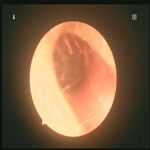
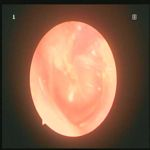
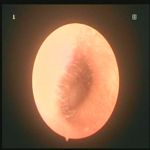
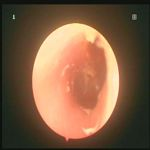
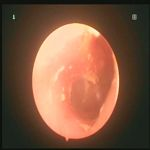
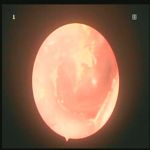
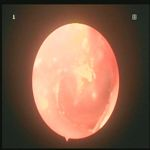
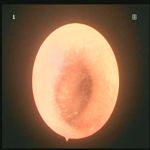
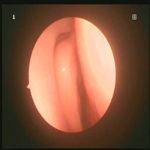
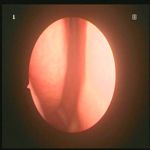
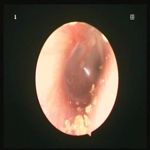
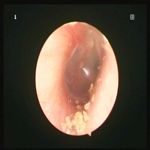
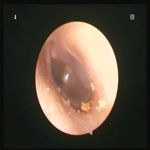
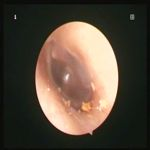
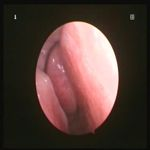
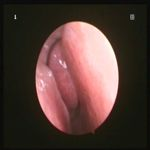
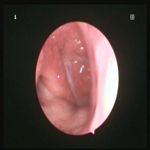
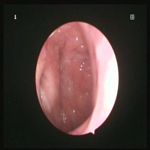
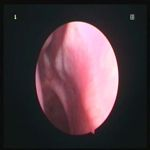
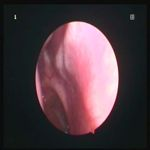
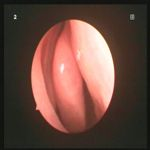
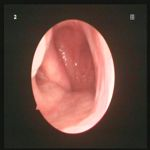
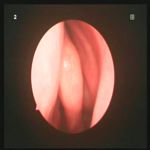
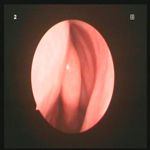
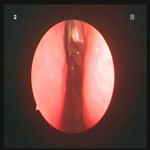
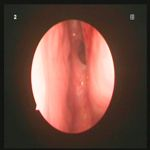
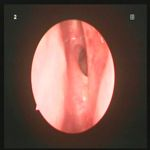
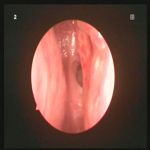
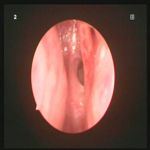
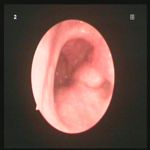
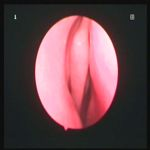
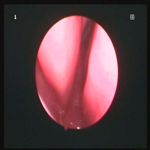
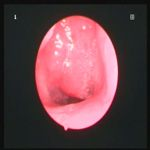
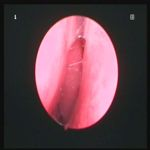
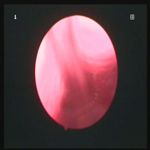
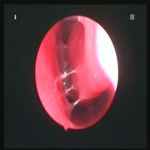
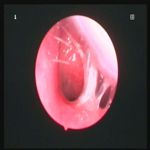
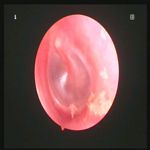
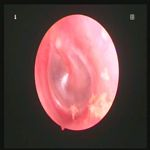
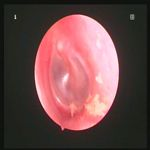
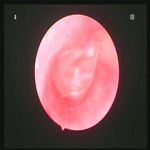
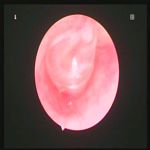
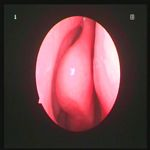
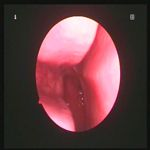
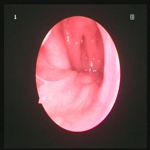
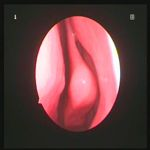
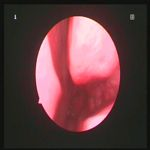
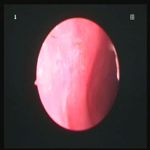
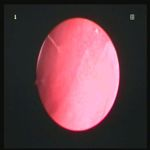
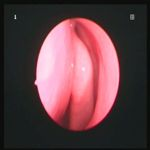
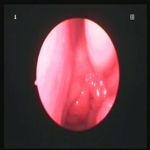
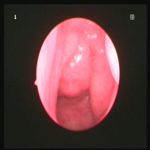
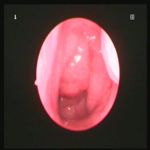
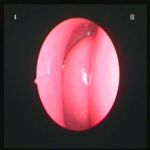
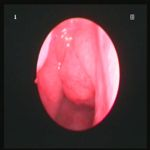
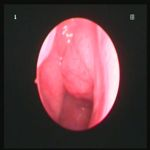
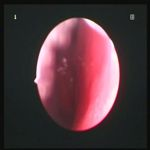
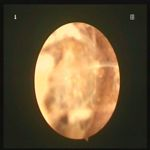
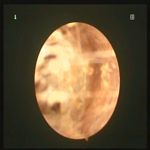
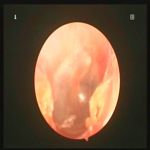
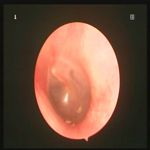
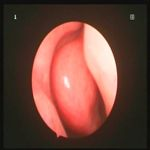
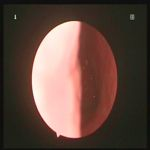
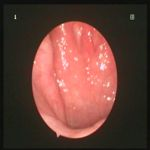
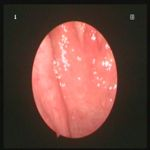
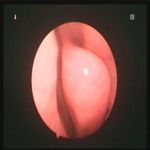
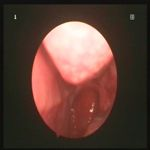
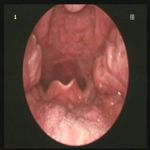
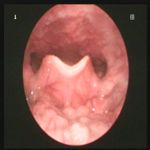
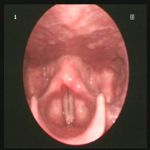
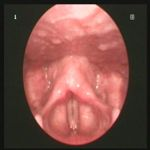
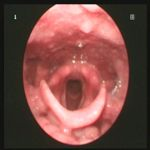
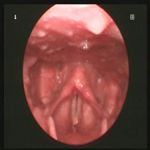

In [60]:
# SHOW EXAMPLES — random VALIDATION cases: images + physician report (ground truth) + V6 report. Display only, nothing written.
import io, base64, html, numpy as np, pandas as pd
from PIL import Image
from IPython.display import HTML, display
OUT = open('/content/v6_out.txt').read().strip(); ROOT = "/content/drive/MyDrive/NoiSoi_Matching"
rep = pd.read_csv(f"{OUT}/final_v6_val/val_reports.csv"); idx = pd.read_csv(f"{OUT}/image_index.csv")
fm = pd.read_csv(f"{ROOT}/final_manifest/final_dataset_manifest.csv", low_memory=False, usecols=["case_id", "ly_do_noi_soi"]).drop_duplicates("case_id").set_index("case_id")
def concl(t): return t.split("Kết luận:")[-1].strip() if isinstance(t, str) else ""
def thumb(i):
    b = io.BytesIO(); Image.open(f"/content/v6_imgs/{i}.jpg").convert("RGB").resize((150, 150)).save(b, "JPEG", quality=80)
    return base64.b64encode(b.getvalue()).decode()
pick = rep.sample(8, random_state=7)
cards = []
for _, r in pick.iterrows():
    ims = idx[idx.case_id == r["case_id"]].sort_values("image_order").img_idx.values[:10]
    same = "✅ same conclusion" if concl(r["gt"]).lower() == concl(r["pred"]).lower() else "≠ different conclusion"
    reason = fm.loc[r["case_id"], "ly_do_noi_soi"]; reason = reason if isinstance(reason, str) else ""
    cards.append(f"<div style='border-top:2px solid #999;padding:8px 0'><b>{r['case_id']}</b> &nbsp;|&nbsp; lý do: {html.escape(reason)} &nbsp;|&nbsp; <i>{same}</i><br>"
                 + "".join(f"<img src='data:image/jpeg;base64,{thumb(i)}' style='margin:2px'>" for i in ims)
                 + f"<table style='width:100%;font-size:13px'><tr><td style='width:50%;vertical-align:top;background:#eef6ee;padding:6px'><b>Bác sĩ (ground truth)</b><br>{html.escape(r['gt']).replace(' | ', '<br>')}</td>"
                 + f"<td style='vertical-align:top;background:#eef0f8;padding:6px'><b>V6 prediction</b><br>{html.escape(r['pred']).replace(' | ', '<br>')}</td></tr></table></div>")
display(HTML("<h3>8 random validation cases (not cherry-picked, seed 7)</h3>" + "".join(cards)))


In [5]:
# STEP 5 — deploy V6 scripts; train report writer (ViT5) in background
import os, subprocess
from google.colab import drive
if not os.path.ismount("/content/drive"): drive.mount("/content/drive")
OUT = open('/content/v6_out.txt').read().strip(); os.makedirs(f'{OUT}/code', exist_ok=True)
open(f'{OUT}/code/v6_train.py', 'w').write('# V6 stage 2: case-level set transformer over frozen image features -> regions + concepts + attributes.\n# Decodes a conclusion by MAP over label-sets seen in train. Evaluates on VALIDATION only.\n# Usage: python v6_train.py OUT FEATS TAG USE_REASON(0/1) [SEED]\nimport os, sys, time, json, re, unicodedata, numpy as np, pandas as pd, torch, torch.nn as nn\nfrom collections import Counter\nfrom sklearn.metrics import roc_auc_score, f1_score\n\nOUT, FEATS, TAG, USE_REASON = sys.argv[1], sys.argv[2], sys.argv[3], int(sys.argv[4])\nSEED = int(sys.argv[5]) if len(sys.argv) > 5 else 0\ntorch.manual_seed(SEED); np.random.seed(SEED)\nROOT = "/content/drive/MyDrive/NoiSoi_Matching"\nRD = f"{OUT}/{TAG}"; os.makedirs(RD, exist_ok=True)\nLOG = open(f"{OUT}/train.log", "a", buffering=1)\ndef log(*a): LOG.write(time.strftime("%H:%M:%S ") + f"[{TAG}] " + " ".join(map(str, a)) + "\\n")\n\n# ---------- data\nidx = pd.read_csv(f"{OUT}/image_index.csv")\nF = np.load(f"{OUT}/{FEATS}").astype(np.float32)\nF = (F - F.mean(0)) / (F.std(0) + 1e-6)\nm = pd.read_csv(f"{ROOT}/baseline_model_v4/v4_training_manifest.csv")\nst = pd.read_csv(f"{ROOT}/v3_ontology_v2/v3_structured_targets_v2_2.csv", low_memory=False)\nfm = pd.read_csv(f"{ROOT}/final_manifest/final_dataset_manifest.csv", low_memory=False).drop_duplicates("case_id").set_index("case_id")\nREGS = ["tai", "hoc_mui", "hong_mui", "hong_thanh_quan", "hong_mieng"]\nCC = [c for c in st.columns if c.startswith(("concept__", "negative__", "attribute__"))]\nst = st.set_index("case_id")\ncases = m[m.case_id.isin(idx.case_id)].reset_index(drop=True)\nYl = st.loc[cases.case_id, CC].fillna(0).values.astype(np.float32)\nYr = np.stack([fm.loc[cases.case_id, r].notna().values & (fm.loc[cases.case_id, r].astype(str).str.strip() != "") for r in REGS], 1).astype(np.float32)\nY = np.concatenate([Yr, Yl], 1); NAMES = [f"region__{r}" for r in REGS] + CC\nlog("cases", len(cases), "targets", Y.shape)\n\ngroups = idx.groupby("case_id")\nMAXI = 24\nimg_lists = {c: g.sort_values("image_order").img_idx.values[:MAXI] for c, g in groups}\n\nR = None\nif USE_REASON:\n    rp = f"{OUT}/reason_e5.npy"\n    if not os.path.exists(rp):\n        from transformers import AutoTokenizer, AutoModel\n        tok = AutoTokenizer.from_pretrained("intfloat/multilingual-e5-base"); enc = AutoModel.from_pretrained("intfloat/multilingual-e5-base").cuda().eval()\n        txt = ["query: " + str(x) if isinstance(x, str) else "query: không rõ" for x in fm.loc[cases.case_id, "ly_do_noi_soi"]]\n        outs = []\n        with torch.no_grad():\n            for i in range(0, len(txt), 256):\n                b = tok(txt[i:i + 256], padding=True, truncation=True, max_length=64, return_tensors="pt").to("cuda")\n                h = enc(**b).last_hidden_state; mk = b["attention_mask"].unsqueeze(-1)\n                outs.append(((h * mk).sum(1) / mk.sum(1)).cpu().numpy())\n        np.save(rp, np.concatenate(outs)); del enc\n    R = np.load(rp).astype(np.float32)\n\nsplit = cases.split.values\ntr, va = np.where(split == "train")[0], np.where(split == "val")[0]\n\ndef batch(ix, train):\n    B = len(ix); X = np.zeros((B, MAXI, F.shape[1]), np.float32); M = np.zeros((B, MAXI), bool); P = np.zeros((B, MAXI), np.int64)\n    for j, i in enumerate(ix):\n        il = img_lists[cases.case_id[i]]\n        if train and len(il) > 2 and np.random.rand() < 0.5:   # image dropout augmentation\n            keep = np.sort(np.random.choice(len(il), max(2, int(len(il) * np.random.uniform(.6, 1))), replace=False)); il = il[keep]\n        X[j, :len(il)] = F[il]; M[j, :len(il)] = True; P[j, :len(il)] = np.arange(len(il))\n    t = lambda a: torch.from_numpy(a).cuda()\n    return t(X), t(M), t(P), (t(R[ix]) if R is not None else None), t(Y[ix])\n\n# ---------- model\nclass Net(nn.Module):\n    def __init__(s, din, nout, d=512):\n        super().__init__()\n        s.proj = nn.Sequential(nn.LayerNorm(din), nn.Dropout(0.2), nn.Linear(din, d))\n        s.pos = nn.Embedding(MAXI, d); s.cls = nn.Parameter(torch.zeros(1, 1, d))\n        s.rproj = nn.Linear(768, d) if USE_REASON else None\n        s.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 8, 4 * d, 0.2, batch_first=True, norm_first=True), 3)\n        s.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.2), nn.Linear(d, nout))\n    def forward(s, X, M, P, Rr, emb=False):\n        h = s.proj(X) + s.pos(P); B = len(h)\n        toks = [s.cls.expand(B, -1, -1)]; masks = [torch.ones(B, 1, dtype=torch.bool, device=h.device)]\n        if s.rproj is not None: toks.append(s.rproj(Rr).unsqueeze(1)); masks.append(masks[0])\n        h = torch.cat(toks + [h], 1); mk = torch.cat(masks + [M], 1)\n        z = s.enc(h, src_key_padding_mask=~mk)[:, 0]\n        return (s.head(z), z) if emb else s.head(z)\n\nnet = Net(F.shape[1], Y.shape[1]).cuda()\npos = Y[tr].mean(0); pw = torch.tensor(np.clip((1 - pos) / np.maximum(pos, 1e-4), 1, 30) ** 0.5).cuda()\nlossf = nn.BCEWithLogitsLoss(pos_weight=pw)\nEP, BS = 60, 64\nopt = torch.optim.AdamW(net.parameters(), lr=3e-4, weight_decay=0.05)\nsched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-4, total_steps=EP * (len(tr) // BS + 1), pct_start=0.1)\n\ndef predict(ix):\n    net.eval(); ps, zs = [], []\n    with torch.no_grad():\n        for i in range(0, len(ix), 256):\n            X, M, P, Rr, _ = batch(ix[i:i + 256], False); lo, z = net(X, M, P, Rr, emb=True)\n            ps.append(torch.sigmoid(lo).cpu().numpy()); zs.append(z.cpu().numpy())\n    return np.concatenate(ps), np.concatenate(zs)\n\ndef macro_auc(Yt, Pp):\n    a = [roc_auc_score(Yt[:, j], Pp[:, j]) for j in range(Yt.shape[1]) if 0 < Yt[:, j].sum() < len(Yt)]\n    return float(np.mean(a))\n\nbest, bad, t0 = -1, 0, time.time()\nfor ep in range(EP):\n    net.train(); perm = np.random.permutation(tr); tl = 0\n    for i in range(0, len(perm), BS):\n        X, M, P, Rr, Yb = batch(perm[i:i + BS], True)\n        loss = lossf(net(X, M, P, Rr), Yb); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); sched.step(); tl += loss.item()\n    pv, _ = predict(va); auc = macro_auc(Y[va], pv)\n    log(f"ep {ep} loss {tl / (len(perm) / BS):.4f} val_macroAUC {auc:.4f} {time.time() - t0:.0f}s")\n    if auc > best: best, bad = auc, 0; torch.save(net.state_dict(), f"{RD}/model.pt")\n    else:\n        bad += 1\n        if bad >= 12: break\nnet.load_state_dict(torch.load(f"{RD}/model.pt"))\n\n# ---------- evaluation on validation\npv, zv = predict(va); ptr, ztr = predict(tr)\nYv = Y[va]\nres = {"tag": TAG, "use_reason": USE_REASON, "val_macroAUC": macro_auc(Yv, pv)}\nper = []\nfor j, n in enumerate(NAMES):\n    npos = int(Yv[:, j].sum())\n    if 0 < npos < len(Yv):\n        # threshold chosen on train predictions to maximise F1 (no val leakage)\n        ths = np.linspace(0.05, 0.95, 19); th = ths[np.argmax([f1_score(Y[tr, j], ptr[:, j] > t, zero_division=0) for t in ths])]\n        per.append(dict(label=n, val_pos=npos, auc=roc_auc_score(Yv[:, j], pv[:, j]), f1=f1_score(Yv[:, j], pv[:, j] > th, zero_division=0), th=th))\nper = pd.DataFrame(per); per.to_csv(f"{RD}/val_per_label.csv", index=False)\nres["region_acc_exactset"] = float(((pv[:, :5] > 0.5) == Yv[:, :5]).all(1).mean())\nres["concept_macroF1(val_pos>=5)"] = float(per[per.val_pos >= 5].f1.mean())\n\n# conclusion decoding: MAP over label-sets observed in train, emit the most common ket_luan of that set\ndef norm(s): s = unicodedata.normalize("NFC", str(s)).lower(); s = re.sub(r"[^\\w\\s]", " ", s); return " ".join(s.split())\ndef tf1(a, b):\n    a, b = norm(a).split(), norm(b).split()\n    if not a or not b: return float(a == b)\n    c = sum((Counter(a) & Counter(b)).values())\n    if c == 0: return 0.0\n    p, r = c / len(a), c / len(b); return 2 * p * r / (p + r)\nkl = cases.ket_luan.values\nkeys = [tuple(r) for r in Y[tr].astype(int)]\nks = {}\nfor k, i in zip(keys, tr): ks.setdefault(k, []).append(norm(kl[i]))\nuk = list(ks.keys()); U = np.array(uk, np.float32); freq = np.array([len(ks[k]) for k in uk], np.float32)\nbest_text = [Counter(ks[k]).most_common(1)[0][0] for k in uk]\nlp = np.log(np.clip(pv, 1e-4, 1 - 1e-4)); ln = np.log(np.clip(1 - pv, 1e-4, 1 - 1e-4))\nscore = lp @ U.T + ln @ (1 - U).T + 1.0 * np.log(freq)[None]\npred_txt = [best_text[j] for j in score.argmax(1)]\n# kNN alternative in embedding space\nzt = ztr / np.linalg.norm(ztr, axis=1, keepdims=True); zq = zv / np.linalg.norm(zv, axis=1, keepdims=True)\nnn_txt = [norm(kl[tr[j]]) for j in (zq @ zt.T).argmax(1)]\ngt = [norm(x) for x in kl[va]]\nfor name, P_ in [("map", pred_txt), ("knn1", nn_txt)]:\n    res[f"concl_{name}_exact"] = float(np.mean([a == b for a, b in zip(P_, gt)]))\n    res[f"concl_{name}_tokenF1"] = float(np.mean([tf1(a, b) for a, b in zip(P_, gt)]))\n    res[f"concl_{name}_unique"] = len(set(P_))\n# baselines on the same val cases\nreg_key = ["".join(map(str, r)) for r in Y[:, :5].astype(int)]\nlut = {}\nfor i in tr: lut.setdefault(reg_key[i], []).append(norm(kl[i]))\nlut = {k: Counter(v).most_common(1)[0][0] for k, v in lut.items()}\ntop = Counter(norm(kl[i]) for i in tr).most_common(1)[0][0]\nlk = [lut.get(reg_key[i], top) for i in va]\nres["baseline_lookup_trueRegion_exact"] = float(np.mean([a == b for a, b in zip(lk, gt)]))\nres["baseline_lookup_trueRegion_tokenF1"] = float(np.mean([tf1(a, b) for a, b in zip(lk, gt)]))\n# "no pathology" handling\nkb = [n for n in NAMES if "khong_thay_benh_ly" in n or n.startswith("negative__")]\nres["normal_labels_auc"] = {n: float(per.set_index("label").auc.get(n, np.nan)) for n in kb}\npd.DataFrame({"case_id": cases.case_id.values[va], "gt": gt, "pred_map": pred_txt, "pred_knn1": nn_txt}).to_csv(f"{RD}/val_conclusions.csv", index=False)\nnp.save(f"{RD}/val_probs.npy", pv)\nnp.save(f"{RD}/val_map_labels.npy", U[score.argmax(1)]); json.dump(NAMES, open(f"{RD}/label_names.json", "w"))\nnp.save(f"{RD}/val_case_ids.npy", cases.case_id.values[va].astype(str))\njson.dump(res, open(f"{RD}/val_metrics.json", "w"), indent=1, ensure_ascii=False)\nlog("RESULT", json.dumps(res, ensure_ascii=False))\nlog("DONE")\n')
open(f'{OUT}/code/v6_writer.py', 'w').write('# V6 stage 3: report writer. Seq2seq (ViT5-base) from structured labels (+ reason) -> full ENT report text.\n# Trained on ground-truth labels with noise; evaluated on VALIDATION with (a) oracle labels and (b) stage-2 predicted labels.\n# Usage: python v6_writer.py OUT STAGE2_TAG [eval]   (without \'eval\': train + oracle eval; with \'eval\': load model, eval oracle+predicted)\nimport os, sys, time, json, re, random, unicodedata, numpy as np, pandas as pd, torch\nfrom collections import Counter\nOUT, S2 = sys.argv[1], sys.argv[2]; EVAL_ONLY = len(sys.argv) > 3 and sys.argv[3] == "eval"\nROOT = "/content/drive/MyDrive/NoiSoi_Matching"\nRD = f"{OUT}/writer"; os.makedirs(RD, exist_ok=True)\nLOG = open(f"{OUT}/train.log", "a", buffering=1)\ndef log(*a): LOG.write(time.strftime("%H:%M:%S ") + "[writer] " + " ".join(map(str, a)) + "\\n")\nrandom.seed(0); np.random.seed(0); torch.manual_seed(0)\n\nm = pd.read_csv(f"{ROOT}/baseline_model_v4/v4_training_manifest.csv")\nst = pd.read_csv(f"{ROOT}/v3_ontology_v2/v3_structured_targets_v2_2.csv", low_memory=False).set_index("case_id")\nfm = pd.read_csv(f"{ROOT}/final_manifest/final_dataset_manifest.csv", low_memory=False).drop_duplicates("case_id").set_index("case_id")\nREGS = ["tai", "hoc_mui", "hong_mui", "hong_thanh_quan", "hong_mieng"]\nNAMES = [f"region__{r}" for r in REGS] + [c for c in st.columns if c.startswith(("concept__", "negative__", "attribute__"))]\nHEAD = {"tai": "Tai", "hoc_mui": "Hốc mũi", "hong_mui": "Họng mũi", "hong_thanh_quan": "Họng thanh quản", "hong_mieng": "Họng miệng"}\ndef clean(x): return " ".join(str(x).split()) if isinstance(x, str) and x.strip() else ""\ndef report(cid):\n    r = fm.loc[cid]; parts = [f"{HEAD[k]}: {clean(r[k])}" for k in REGS if clean(r[k])]\n    return " | ".join(parts + [f"Kết luận: {clean(r[\'ket_luan\'])}"])\ndef lab_vec(cid):\n    r = fm.loc[cid]; reg = [float(bool(clean(r[k]))) for k in REGS]\n    return np.array(reg + list(st.loc[cid, NAMES[5:]].fillna(0).values), np.float32)\ndef src(vec, cid):\n    on = [NAMES[j].split("__", 1)[1] for j in range(len(NAMES)) if vec[j] > 0.5]\n    reason = clean(fm.loc[cid, "ly_do_noi_soi"]) or "không rõ"\n    return f"lý do: {reason} | nhãn: " + ", ".join(on)\n\ncases = m[m.case_id.isin(fm.index)]\ntr = cases[cases.split == "train"].case_id.tolist(); va = cases[cases.split == "val"].case_id.tolist()\nVtr = {c: lab_vec(c) for c in tr}; tgt = {c: report(c) for c in tr + va}\n\nfrom transformers import AutoTokenizer, AutoModelForSeq2SeqLM\nMN = "VietAI/vit5-base"\nif EVAL_ONLY: MN = f"{RD}/model"\ntok = AutoTokenizer.from_pretrained(MN); model = AutoModelForSeq2SeqLM.from_pretrained(MN).cuda()\nopt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)\nEP, BS = (0 if EVAL_ONLY else 10), 32; steps = EP * (len(tr) // BS + 1)\nsch = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-4, total_steps=max(steps, 1), pct_start=0.05)\ndef noisy(v):\n    v = v.copy(); on = np.where(v[5:] > 0.5)[0] + 5\n    if len(on) and random.random() < 0.15: v[random.choice(on)] = 0     # drop a true label\n    if random.random() < 0.15: v[random.randrange(5, len(v))] = 1        # add a spurious label\n    return v\nt0 = time.time()\nfor ep in range(EP):\n    model.train(); random.shuffle(tr); tl = 0\n    for i in range(0, len(tr), BS):\n        b = tr[i:i + BS]\n        x = tok([src(noisy(Vtr[c]), c) for c in b], padding=True, truncation=True, max_length=160, return_tensors="pt").to("cuda")\n        y = tok([tgt[c] for c in b], padding=True, truncation=True, max_length=320, return_tensors="pt").input_ids.to("cuda")\n        y[y == tok.pad_token_id] = -100\n        with torch.autocast("cuda", dtype=torch.bfloat16):\n            loss = model(**x, labels=y).loss\n        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sch.step(); tl += loss.item()\n    log(f"ep {ep} loss {tl / (len(tr) / BS):.4f} {time.time() - t0:.0f}s")\nif not EVAL_ONLY: model.save_pretrained(f"{RD}/model"); tok.save_pretrained(f"{RD}/model")\n\ndef gen(srcs):\n    model.eval(); outs = []\n    with torch.no_grad():\n        for i in range(0, len(srcs), 64):\n            x = tok(srcs[i:i + 64], padding=True, truncation=True, max_length=160, return_tensors="pt").to("cuda")\n            with torch.autocast("cuda", dtype=torch.bfloat16):\n                o = model.generate(**x, max_new_tokens=320, num_beams=4)\n            outs += tok.batch_decode(o, skip_special_tokens=True)\n    return outs\ndef norm(s): s = unicodedata.normalize("NFC", str(s)).lower(); s = re.sub(r"[^\\w\\s]", " ", s); return " ".join(s.split())\ndef tf1(a, b):\n    a, b = norm(a).split(), norm(b).split()\n    if not a or not b: return float(a == b)\n    c = sum((Counter(a) & Counter(b)).values())\n    if c == 0: return 0.0\n    p, r = c / len(a), c / len(b); return 2 * p * r / (p + r)\ndef sections(t):\n    d = {}\n    for part in t.split("|"):\n        if ":" in part:\n            k, v = part.split(":", 1); d[norm(k)] = v.strip()\n    return d\n\nmodes = ["oracle"]\nif EVAL_ONLY:\n    assert json.load(open(f"{OUT}/{S2}/label_names.json")) == NAMES, "label order mismatch"\n    pred_lab = np.load(f"{OUT}/{S2}/val_map_labels.npy"); vids = list(np.load(f"{OUT}/{S2}/val_case_ids.npy"))\n    vmap = dict(zip(vids, pred_lab)); modes = ["oracle", "predicted"]\nres = {}; rows = {"case_id": va, "gt": [tgt[c] for c in va]}\nfor mode in modes:\n    srcs = [src(lab_vec(c) if mode == "oracle" else vmap[c], c) for c in va]\n    out = gen(srcs); rows[mode] = out\n    gs, ps = [sections(tgt[c]) for c in va], [sections(o) for o in out]\n    kc = norm("Kết luận")\n    res[f"{mode}_concl_exact"] = float(np.mean([norm(p.get(kc, "")) == norm(g.get(kc, "")) for p, g in zip(ps, gs)]))\n    res[f"{mode}_concl_tokenF1"] = float(np.mean([tf1(p.get(kc, ""), g.get(kc, "")) for p, g in zip(ps, gs)]))\n    res[f"{mode}_concl_unique"] = len(set(norm(p.get(kc, "")) for p in ps))\n    res[f"{mode}_full_tokenF1"] = float(np.mean([tf1(o, tgt[c]) for o, c in zip(out, va)]))\n    for k in REGS:\n        hk = norm(HEAD[k]); has = [hk in g for g in gs]\n        res[f"{mode}_{k}_presence_acc"] = float(np.mean([(hk in p) == h for p, h in zip(ps, has)]))\n        res[f"{mode}_{k}_findingsF1_when_present"] = float(np.mean([tf1(p.get(hk, ""), g[hk]) for p, g, h in zip(ps, gs, has) if h])) if any(has) else None\nsfx = f"_{S2}" if EVAL_ONLY else "_oracle"\npd.DataFrame(rows).to_csv(f"{RD}/val_reports{sfx}.csv", index=False)\njson.dump(res, open(f"{RD}/val_metrics{sfx}.json", "w"), indent=1, ensure_ascii=False)\nlog("RESULT", json.dumps(res, ensure_ascii=False)); log("DONE")\n')
subprocess.Popen(f"cd '{OUT}/code' && nohup sh -c \"python v6_writer.py '{OUT}' none\" >> '{OUT}/train.stdout' 2>&1 &", shell=True)
print('launched:', "python v6_writer.py '{OUT}' none")


launched: python v6_writer.py '{OUT}' none
